# Baseline vs Adaptive AIMD vs CUBIC AIMD — Three-Way Comparison

Initial visualization for the final TCC campaign. Three controllers across six scenarios (A–F).

- `baseline` = fixed bitrate, no controller
- `adaptive` = β=0.7 hand-rolled two-phase AIMD (the `adaptive/` June 1 campaign, reused)
- `cubic` = β=0.7 AIMD with CUBIC fast convergence + cubic recovery curve (K=15s), the contribution

Notes on the rating scale: **1 = best, 5 = worst** (latency / quality / stability).

See [[final-campaign-protocol]] for the methodology spec.


In [1]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('../../results')
DIRS = {
    'baseline': RESULTS_DIR / 'baseline',
    'adaptive': RESULTS_DIR / 'adaptive',
    'cubic':    RESULTS_DIR / 'cubic',
}
SCENARIOS = ['A','B','C','D','E','F']

# Each scenario's shaping schedule as a list of (t_start, t_end, cap_mbps).
# Outside listed windows the channel is unshaped (~1 Gbit). Source:
# testbed/lib/scenarios.sh.
SHAPING = {
    'A': [(80, 160, 8)],
    'B': [(60, 90, 16), (90, 120, 12), (120, 160, 8)],
    'C': [(40, 120, 14), (120, 200, 10)],
    'D': [(30, 60, 10), (90, 120, 10), (150, 180, 10), (210, 240, 10)],
    'E': [(40, 200, 4)],
    'F': [(0, 160, 6)],
}

COLOR = {'baseline':'#888888', 'adaptive':'#1f77b4', 'cubic':'#d62728'}
LABEL = {'baseline':'baseline', 'adaptive':'adaptive AIMD', 'cubic':'CUBIC AIMD'}


## 1. Load CSVs and notes


In [2]:
def find_run(directory: Path, scenario: str):
    csvs = sorted(directory.glob(f'{scenario}_run0_*.csv'))
    if not csvs:
        return None, None
    csv = csvs[0]
    notes = csv.with_suffix('.notes.txt')
    return csv, (notes if notes.exists() else None)

def parse_notes(path: Path):
    if path is None:
        return {}
    out = {}
    txt = path.read_text()
    for line in txt.splitlines():
        if ':' in line and not line.startswith('#'):
            k, v = line.split(':', 1)
            out[k.strip()] = v.strip()
    if '# Gameplay note' in txt:
        out['note'] = txt.split('# Gameplay note',1)[1].strip().splitlines()
        out['note'] = out['note'][0] if out['note'] else ''
    return out

def load_run(mode: str, scenario: str):
    csv_path, notes_path = find_run(DIRS[mode], scenario)
    if csv_path is None:
        return None
    df = pd.read_csv(csv_path)
    df['t_s'] = df['elapsed_ms'] / 1000.0
    return {'df': df, 'notes': parse_notes(notes_path), 'csv': csv_path}

data = {m: {s: load_run(m, s) for s in SCENARIOS} for m in DIRS}


## 2. Summary metrics table

Per scenario × controller: peak / p99 / p95 / p50 RTT, controller activity, stalls.


In [3]:
def summarize(df):
    rtt = df['rtt_ms'].values
    target = df['target_kbps'].values
    return {
        'peak_rtt': float(rtt.max()),
        'p99_rtt':  float(np.percentile(rtt, 99)),
        'p95_rtt':  float(np.percentile(rtt, 95)),
        'p50_rtt':  float(np.median(rtt)),
        'mean_rtt': float(rtt.mean()),
        'over_100_pct': float(100 * (rtt > 100).mean()),
        'decreases': int(((np.diff(target)) < -1).sum()),
        'increases': int(((np.diff(target)) >  1).sum()),
        'stalls': int(df['stalls'].sum()),
        'stall_ms_total': float(df['stall_ms'].sum()),
        'idr_frames': int(df['idr_frames'].sum()),
        'avg_send_ms': float(df['avg_send_ms'].mean()),
        'avg_bitrate_kbps': float(df['bitrate_kbps'].mean()),
        'duration_s': float(df['t_s'].iloc[-1]),
    }

rows = []
for s in SCENARIOS:
    for m in DIRS:
        if data[m][s] is None: continue
        st = summarize(data[m][s]['df'])
        n = data[m][s]['notes']
        rows.append({
            'scenario': s,
            'controller': m,
            **st,
            'rating_lat': n.get('rating_latency','-'),
            'rating_qual': n.get('rating_quality','-'),
            'rating_stab': n.get('rating_stability','-'),
            'note': n.get('note',''),
        })
summary = pd.DataFrame(rows)
display(summary[['scenario','controller','peak_rtt','p99_rtt','p95_rtt','p50_rtt','decreases','increases','stalls','stall_ms_total','idr_frames','rating_lat','rating_qual','rating_stab']].round(0))


,scenario,controller,peak_rtt,p99_rtt,p95_rtt,p50_rtt,decreases,increases,stalls,stall_ms_total,idr_frames,rating_lat,rating_qual,rating_stab
0,A,baseline,1854.0,1801.0,1723.0,4.0,0,0,43,49337.0,10,5,1,5
1,A,adaptive,1786.0,1713.0,52.0,4.0,7,25,4,4408.0,35,3,1,3
2,A,cubic,1025.0,882.0,175.0,16.0,9,82,0,0.0,97,3,2,3
3,B,baseline,1551.0,1481.0,1321.0,5.0,0,0,50,43550.0,27,4,1,4
4,B,adaptive,575.0,544.0,194.0,4.0,7,22,0,0.0,30,1,1,2
5,B,cubic,532.0,473.0,123.0,18.0,7,67,0,0.0,78,3,2,2
6,C,baseline,1565.0,1541.0,1481.0,6.0,0,0,107,87452.0,104,4,1,4
7,C,adaptive,733.0,504.0,116.0,5.0,7,28,0,0.0,36,1,1,1
8,C,cubic,639.0,563.0,294.0,13.0,12,115,0,0.0,133,2,1,3
9,D,baseline,1583.0,1531.0,1442.0,16.0,0,0,103,91501.0,97,4,1,3


## 3. Per-scenario RTT timelines

All three controllers overlaid. Vertical bands show the shaping window where defined.


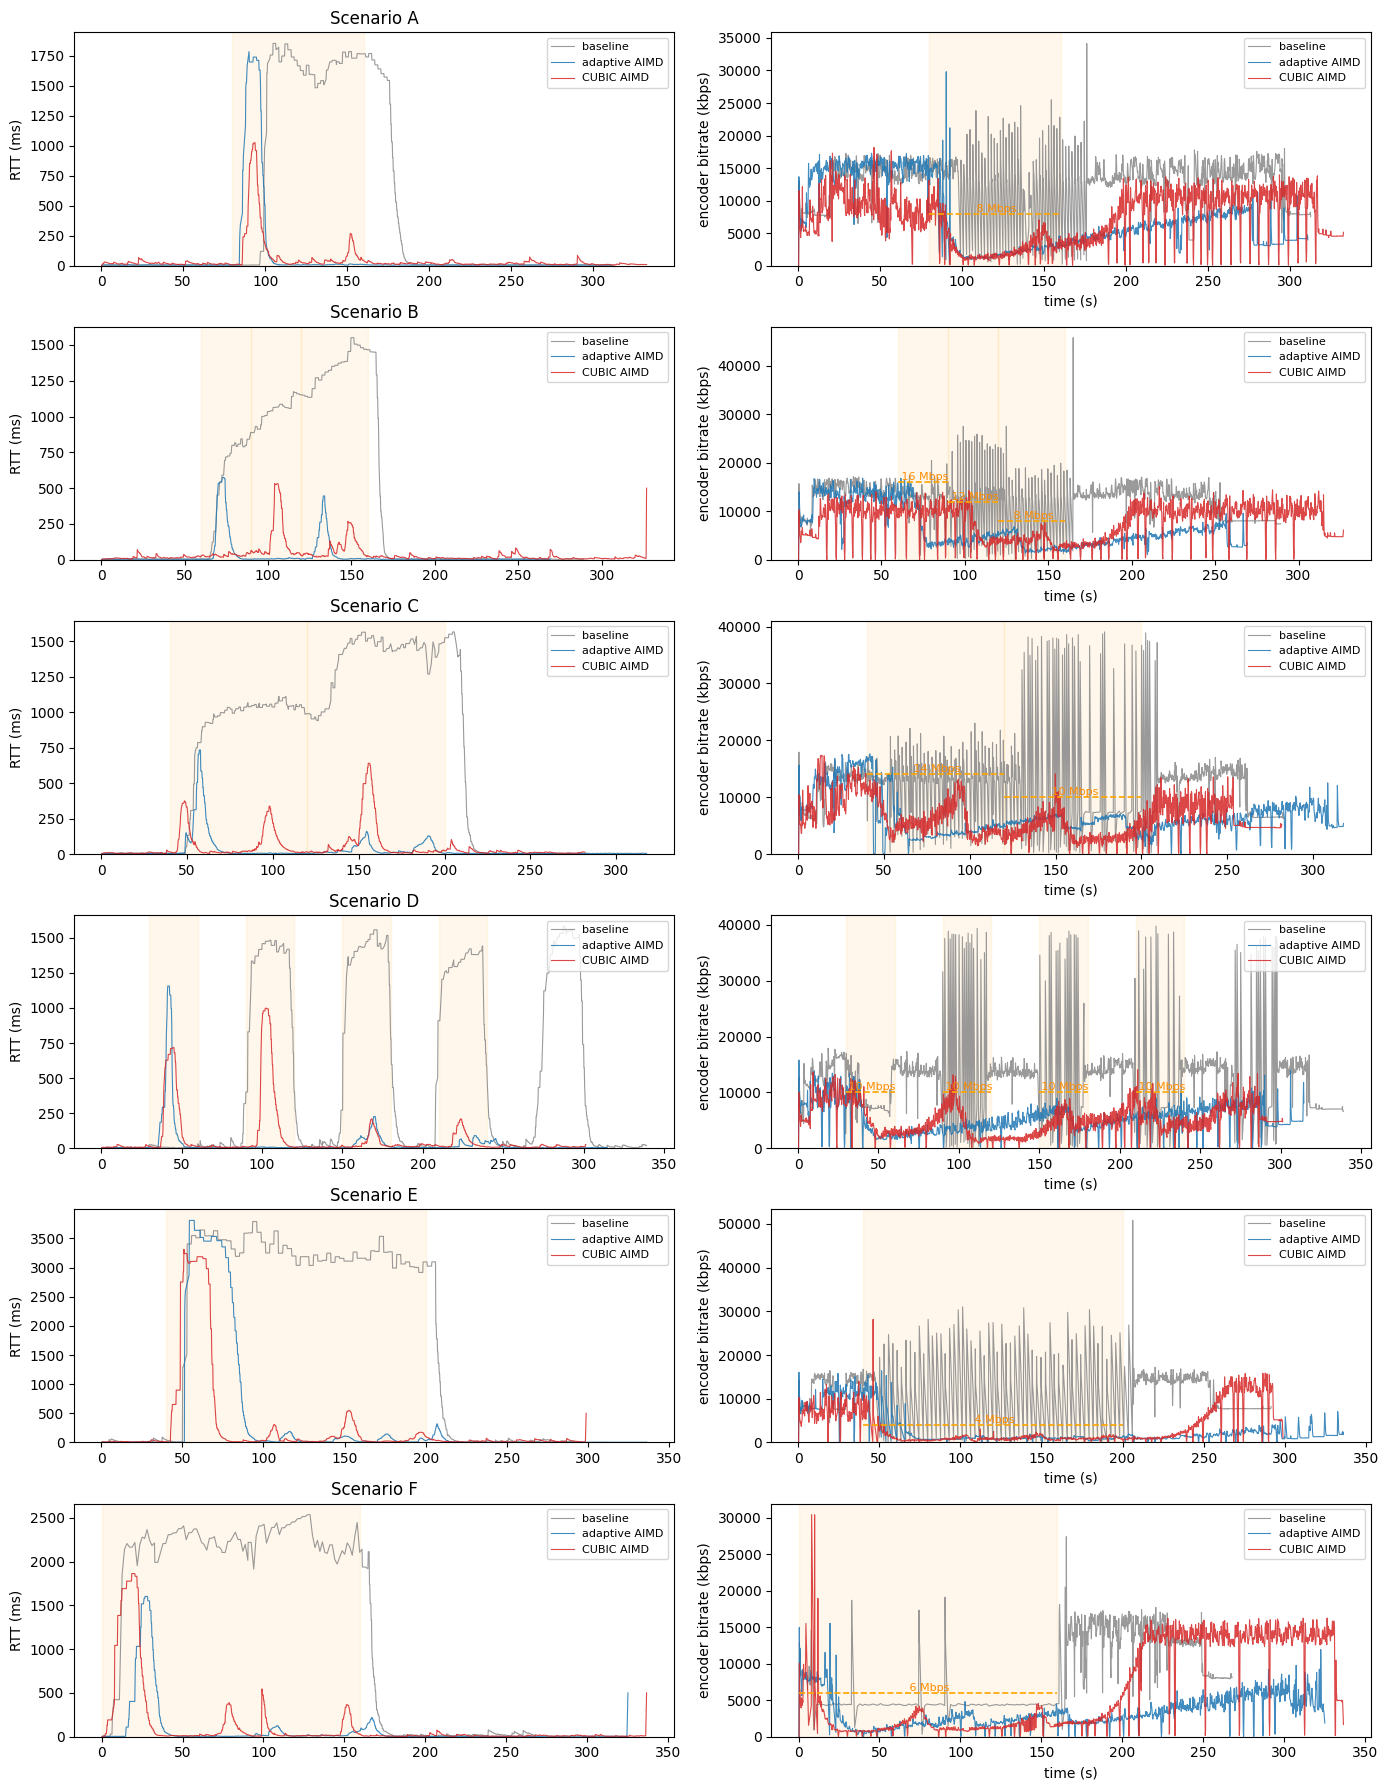

In [4]:
def plot_timeline(scenario: str, ax_rtt, ax_br):
    for m in ['baseline','adaptive','cubic']:
        d = data[m][scenario]
        if d is None: continue
        df = d['df']
        ax_rtt.plot(df['t_s'], df['rtt_ms'], label=LABEL[m], color=COLOR[m], lw=0.8, alpha=0.85)
        ax_br.plot(df['t_s'], df['bitrate_kbps'], label=LABEL[m], color=COLOR[m], lw=0.8, alpha=0.85)
    # Draw shaping windows + cap line per segment
    for (a, b, cap_mbps) in SHAPING.get(scenario, []):
        cap_kbps = cap_mbps * 1000
        ax_rtt.axvspan(a, b, alpha=0.08, color='orange')
        ax_br.axvspan(a, b, alpha=0.08, color='orange')
        ax_br.hlines(cap_kbps, a, b, colors='orange', linestyles='--', lw=1.2)
        # Label the cap value in the middle of the segment
        ax_br.text((a + b) / 2, cap_kbps, f' {cap_mbps} Mbps',
                   color='darkorange', fontsize=8, va='bottom', ha='center')
    ax_rtt.set_ylabel('RTT (ms)')
    ax_rtt.set_title(f'Scenario {scenario}')
    ax_rtt.legend(loc='upper right', fontsize=8)
    ax_rtt.set_ylim(0, None)
    ax_br.set_xlabel('time (s)')
    ax_br.set_ylabel('encoder bitrate (kbps)')
    ax_br.legend(loc='upper right', fontsize=8)
    ax_br.set_ylim(0, None)

fig, axes = plt.subplots(len(SCENARIOS), 2, figsize=(14, 3*len(SCENARIOS)))
for i, s in enumerate(SCENARIOS):
    plot_timeline(s, axes[i,0], axes[i,1])
plt.tight_layout()
plt.savefig('timelines.png', dpi=120, bbox_inches='tight')
plt.show()


## 4. Cross-scenario summary bars

Headline: peak RTT, total stall time, IDR-frame count, and channel use during shaping.


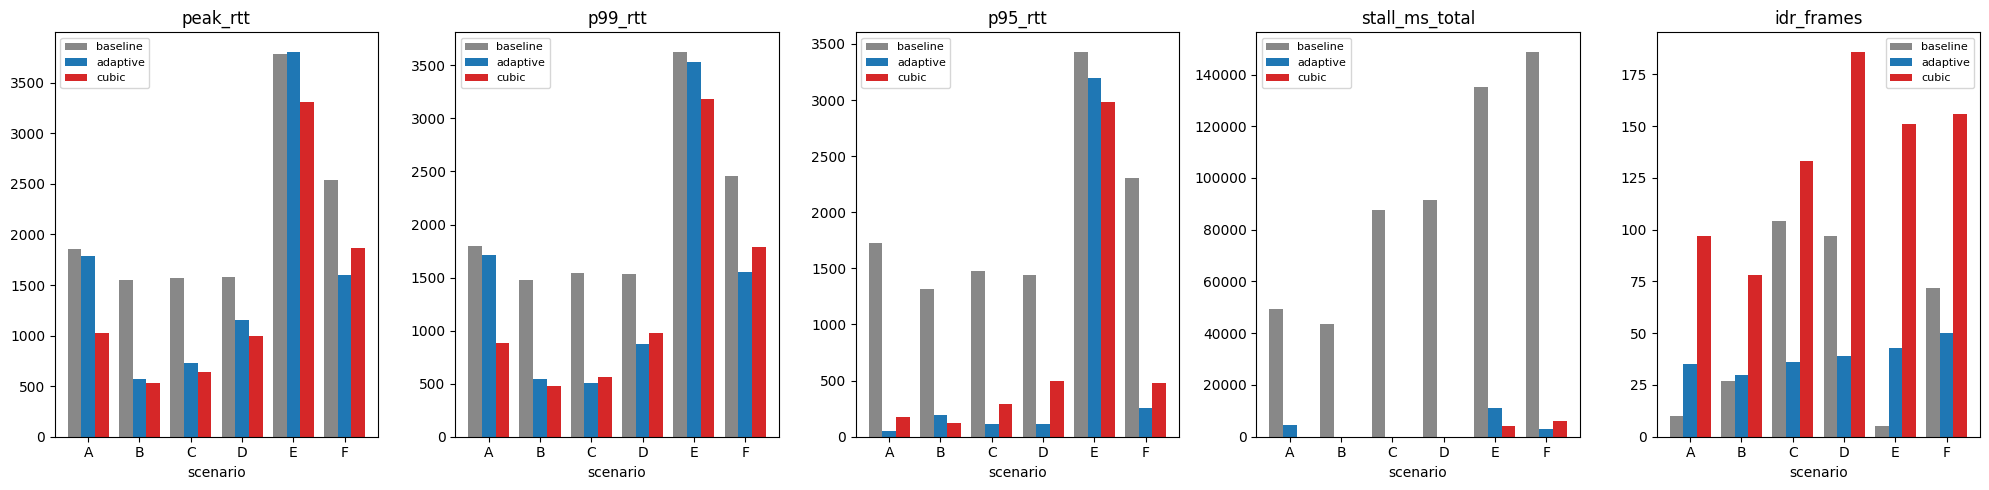

In [5]:
metrics = ['peak_rtt', 'p99_rtt', 'p95_rtt', 'stall_ms_total', 'idr_frames']
fig, axes = plt.subplots(1, len(metrics), figsize=(20, 5))
for ax, metric in zip(axes, metrics):
    pivot = summary.pivot(index='scenario', columns='controller', values=metric)[['baseline','adaptive','cubic']]
    pivot.plot.bar(ax=ax, color=[COLOR[c] for c in pivot.columns], width=0.8)
    ax.set_title(metric)
    ax.set_xlabel('scenario')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('summary_bars.png', dpi=120, bbox_inches='tight')
plt.show()


## 5. Subjective ratings

Lower is better. 1 = excellent, 5 = unplayable.


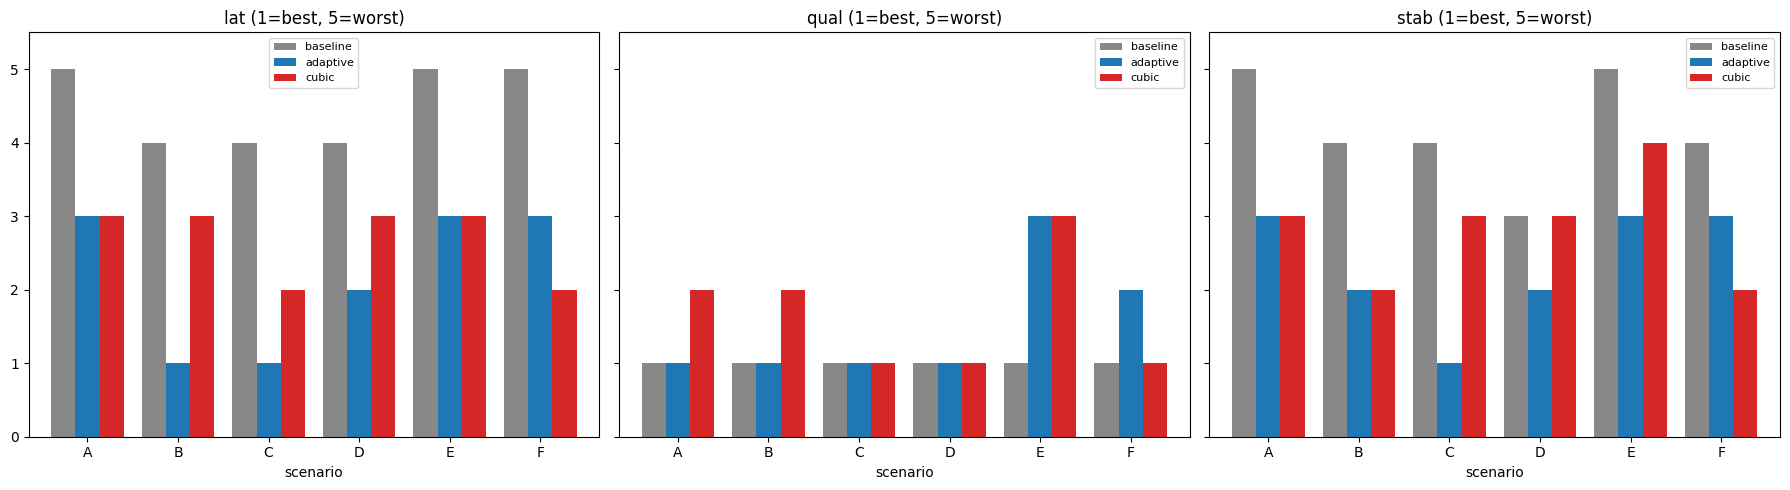

controller adaptive           baseline           cubic          
metric          lat qual stab      lat qual stab   lat qual stab
scenario                                                        
A               3.0  1.0  3.0      5.0  1.0  5.0   3.0  2.0  3.0
B               1.0  1.0  2.0      4.0  1.0  4.0   3.0  2.0  2.0
C               1.0  1.0  1.0      4.0  1.0  4.0   2.0  1.0  3.0
D               2.0  1.0  2.0      4.0  1.0  3.0   3.0  1.0  3.0
E               3.0  3.0  3.0      5.0  1.0  5.0   3.0  3.0  4.0
F               3.0  2.0  3.0      5.0  1.0  4.0   2.0  1.0  2.0

In [6]:
rating_rows = []
for _, r in summary.iterrows():
    for k in ('lat','qual','stab'):
        v = r[f'rating_{k}']
        if v == '-': continue
        try: rating_rows.append({'scenario': r['scenario'], 'controller': r['controller'], 'metric': k, 'value': int(v)})
        except: pass
ratings = pd.DataFrame(rating_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, m in zip(axes, ['lat','qual','stab']):
    sub = ratings[ratings['metric']==m]
    pivot = sub.pivot(index='scenario', columns='controller', values='value')[['baseline','adaptive','cubic']]
    pivot.plot.bar(ax=ax, color=[COLOR[c] for c in pivot.columns], width=0.8)
    ax.set_title(f'{m} (1=best, 5=worst)')
    ax.set_ylim(0, 5.5)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('ratings.png', dpi=120, bbox_inches='tight')
plt.show()

display(ratings.pivot_table(index='scenario', columns=['controller','metric'], values='value'))


## 6. CUBIC vs adaptive: head-to-head deltas

Where does the contribution actually win, where does it lose?


In [7]:
compare = summary.pivot(index='scenario', columns='controller', values=['peak_rtt','p99_rtt','p95_rtt','p50_rtt','stall_ms_total','idr_frames','decreases','increases'])

delta = pd.DataFrame({
    'peak_rtt_Δ_ms': summary[summary.controller=='cubic'].set_index('scenario')['peak_rtt'] - summary[summary.controller=='adaptive'].set_index('scenario')['peak_rtt'],
    'peak_rtt_Δ_pct': 100*(summary[summary.controller=='cubic'].set_index('scenario')['peak_rtt'] - summary[summary.controller=='adaptive'].set_index('scenario')['peak_rtt']) / summary[summary.controller=='adaptive'].set_index('scenario')['peak_rtt'],
    'p99_rtt_Δ_pct': 100*(summary[summary.controller=='cubic'].set_index('scenario')['p99_rtt'] - summary[summary.controller=='adaptive'].set_index('scenario')['p99_rtt']) / summary[summary.controller=='adaptive'].set_index('scenario')['p99_rtt'],
    'p50_rtt_Δ_ms': summary[summary.controller=='cubic'].set_index('scenario')['p50_rtt'] - summary[summary.controller=='adaptive'].set_index('scenario')['p50_rtt'],
    'p95_rtt_Δ_ms': summary[summary.controller=='cubic'].set_index('scenario')['p95_rtt'] - summary[summary.controller=='adaptive'].set_index('scenario')['p95_rtt'],
    'stall_ms_Δ': summary[summary.controller=='cubic'].set_index('scenario')['stall_ms_total'] - summary[summary.controller=='adaptive'].set_index('scenario')['stall_ms_total'],
}).round(0)
display(delta)


,peak_rtt_Δ_ms,peak_rtt_Δ_pct,p99_rtt_Δ_pct,p50_rtt_Δ_ms,p95_rtt_Δ_ms,stall_ms_Δ
scenario,,,,,,
A,-761.0,-43.0,-49.0,12.0,123.0,-4408.0
B,-43.0,-7.0,-13.0,14.0,-71.0,0.0
C,-94.0,-13.0,12.0,8.0,178.0,0.0
D,-158.0,-14.0,12.0,7.0,380.0,0.0
E,-497.0,-13.0,-10.0,18.0,-217.0,-6704.0
F,261.0,16.0,15.0,7.0,217.0,3109.0


## 7. Gameplay notes

Free-form operator notes per run, for context.


In [8]:
note_rows = []
for _, r in summary.iterrows():
    note_rows.append({'scenario': r['scenario'], 'controller': r['controller'], 'note': r['note']})
display(pd.DataFrame(note_rows).pivot(index='scenario', columns='controller', values='note'))


controller,adaptive,baseline,cubic
scenario,,,
A,"Um grande freeze, que foi suavizado e com algu...",Injogavel durante o momento de perda de banda,"Bem laggy all around, mas deu pra jogar!"
B,Muitos poucos travamentos,"Deu pra perceber uma ""escadinha"" de travamento...",O caso mais interessante até agora: até mais o...
C,Muitos poucos travamentos,"Claramente o jogo travava um pouco menos, mas ...",Alguns dips mas em geral não teve grandes trav...
D,"Alguns travamentos, um mais forte no inicio. C...","O mais ok até agora, travou bastante mas por m...",Um grande travamento no meio - em geral experi...
E,"Se segurou muito bom, embora acho que poderia ...","Quando começou a travar, ficou poucos segundos...",Estabilidade ruim throughout. Grande travament...
F,Um pouco travado throughout,Injogavel do minuto 0 ao ~3],"Bem smooth, com leves travamentos e latencia"
